In [1]:
# I want to find the value of t_conv over the production run, and then work out number of convective turnovers simulated.

In [1]:
import numpy as np
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
r_bot = 52239320762.259705
r_top = 175414301920.61127
Nr = 512
# Ntheta = 360
# Nphi = 720
dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [8]:
absolute_path = "/z2/users/cj517/lscaledir_20M/Om0/production_analysis/time_series.dat"

PATTERN = os.path.relpath(absolute_path)

all_files = sorted(glob.glob(PATTERN))

# all_files[0:1]
all_files

['../../../../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/time_series.dat']

In [10]:
save_dir = '20M_Om0/'
omega_dict = {"20M_Om0":0, "20M_invRo2-5":3.9e-6, "20M_invRo2":1.951e-5}
omega = omega_dict[save_dir[:-1]]
omega

0

In [11]:
df = pd.read_csv(all_files[0], delimiter="\s+", index_col="time")
df = df[df["convective_time_vel_1_rms"] > 0]
df

,log_e_kin_tot,log_e_int_tot,convective_time_hp,log_e_int_tot_dupl,angular_momentum,angular_momentum_diff,convective_time_vel_rms,convective_time_vel_1_rms,convective_time_half_hp,convective_time_hp_vel_rms,...,convective_time_vel_1_max,log_e_int_kin,e_grav,e_int_kin_grav,e_int_kin_diff,e_int_kin_grav_diff,log_totkeintv,log_totev,totkeintv_diff,totev_diff
time,,,,,,,,,,,,,,,,,,,,,
60006000.0,43.968264,50.230622,1213000.0,43.97,0.0,0.0,631500.0,1708000.0,546000.0,912000.0,...,31400.0,50.230622,-1.456909e+50,2.437704e+49,0.000000e+00,0.000000e+00,18.822023,17.166956,0.000000e+00,0.000000e+00
60012000.0,43.968373,50.230622,1211000.0,43.97,0.0,0.0,630200.0,1689000.0,544000.0,933000.0,...,33400.0,50.230622,-1.456909e+50,2.437704e+49,2.913481e-10,-2.610016e-09,18.822023,17.166956,6.293556e-10,-1.024106e-08
60018000.0,43.968517,50.230622,1211000.0,43.97,0.0,0.0,629000.0,1672000.0,544000.0,955000.0,...,33000.0,50.230622,-1.456909e+50,2.437704e+49,5.503934e-10,-5.040797e-09,18.822023,17.166956,1.110026e-09,-2.562391e-08
60024000.0,43.968715,50.230622,1209000.0,43.97,0.0,0.0,628200.0,1661000.0,544000.0,976000.0,...,33600.0,50.230622,-1.456909e+50,2.437704e+49,7.668010e-10,-7.262245e-09,18.822023,17.166956,1.404324e-09,-4.832529e-08
60030000.0,43.968935,50.230622,1216000.0,43.97,0.0,0.0,627600.0,1659000.0,545000.0,996000.0,...,31400.0,50.230622,-1.456909e+50,2.437704e+49,8.615714e-10,-8.796903e-09,18.822023,17.166956,1.376887e-09,-7.635844e-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119976000.0,43.954918,50.230622,990100.0,43.95,0.0,0.0,581200.0,1662000.0,476000.0,1330000.0,...,16600.0,50.230623,-1.456914e+50,2.437655e+49,5.740030e-08,-3.438341e-06,18.822024,17.167094,4.826827e-07,4.871612e-05
119982000.0,43.954655,50.230622,992700.0,43.95,0.0,0.0,580700.0,1662000.0,477000.0,1310000.0,...,14600.0,50.230623,-1.456914e+50,2.437655e+49,5.632336e-08,-3.433737e-06,18.822024,17.167094,4.817336e-07,4.878439e-05
119988000.0,43.954384,50.230622,989500.0,43.95,0.0,0.0,580300.0,1661000.0,479000.0,1300000.0,...,14900.0,50.230623,-1.456914e+50,2.437655e+49,5.510760e-08,-3.428250e-06,18.822024,17.167094,4.806192e-07,4.885463e-05


t_conv_mean = 1725413.2


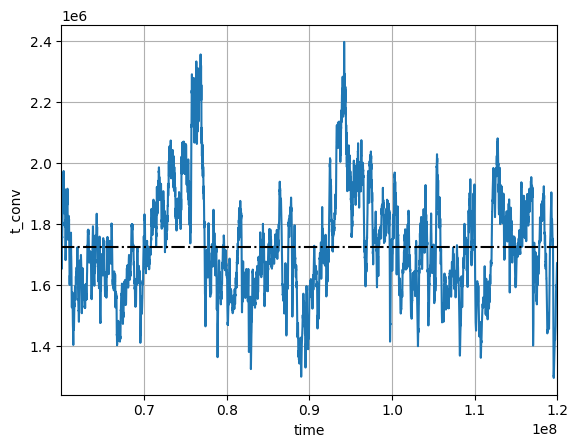

In [13]:
fig, ax = plt.subplots()
ax.plot(df.index,df["convective_time_vel_1_rms"])
ax.grid()
ax.set_xlabel("time")
ax.set_ylabel("t_conv")
ax.set_xlim(df.index.min(), df.index.max())
t_conv_mean = df["convective_time_vel_1_rms"].mean()
print(f"t_conv_mean = {t_conv_mean}")
ax.axhline(t_conv_mean, c= "k", ls="dashdot")
fig.savefig(save_dir + "t_conv_vel_1.png", bbox_inches="tight")

In [14]:
simulation_time = df.index.max() - df.index.min()
convective_turnovers= simulation_time / t_conv_mean
print(f"convective turnovers = {convective_turnovers}")
inv_Rossby = omega * t_conv_mean / (2 * np.pi)
print(f"inv_Rossby = {inv_Rossby}")
with open("20M_convective_turnovers.txt", "a") as f:
    f.write(f"\nmodel:{save_dir[:-1]}\tconvective_turnovers:{convective_turnovers}\tt_conv_mean:{t_conv_mean}\tinv_Rossby:{inv_Rossby}")

convective turnovers = 34.77080156799543
inv_Rossby = 0.0
